In [1]:
import pickle
import numpy as np
import pandas as pd
import xarray as xr
import glob
import copernicusmarine
import netCDF4
import dask
import yaml
import os

In [2]:
from pathlib import Path
from shapely.geometry import Polygon, Point
from matplotlib.patches import Polygon as MplPolygon
import matplotlib.patheffects as path_effects
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [3]:
def inspect_array(arr):
    names = [n for n, v in globals().items() if v is arr]
    name = names[0] if names else "<unknown>"
    print(f"{name}: {type(arr)}, shape={arr.shape}")

In [4]:
def inspect_var(var):
    names = [n for n, v in globals().items() if v is var]
    name = names[0] if names else "<unknown>"
    print(f"{name}: {type(var)}, {var}")

In [5]:
def read_dates(ds):
    #
    # Convert 1D TIME coordinate to 2D numpy datetime64 array
    #
    dates_1d = ds['TIME'].values.astype('datetime64[ns]')
    n_depth = ds.sizes['DEPTH']
    dates_2d = np.tile(dates_1d, (n_depth, 1)).T

    return dates_2d

In [6]:
def plot_profiles(dates_2d, pres, var, ax=None, cmap=None, label=None, title=None, zmin=None, zmax=None, vmin=None, vmax=None):

    common_mask = np.logical_or(pres.mask,var.mask)
    var.mask = common_mask

    if np.all(pres.mask):
        print(f"   PRES is empty, EXIT")
        return
        
    if np.all(var.mask):
        print(f"   {title} is empty")
    
    if cmap is None:
        cmap = 'viridis'

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 2.5))
        
    if (vmin is not None) and (vmax is not None):
        c = ax.scatter(dates_2d, pres, c=var, cmap=cmap, s=8, marker='o', vmin=vmin, vmax=vmax)
    else:
        c = ax.scatter(dates_2d, pres, c=var, cmap=cmap, s=8, marker='o')
        
    if (zmin is not None) and (zmax is not None):
        ax.set_ylim(zmax, zmin)
    else:
        ax.invert_yaxis()
        
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    
    if label is not None:
        plt.colorbar(c, label=label)
        
    ax.set_xlabel('time [YYYY-MM-DD]')
    ax.set_ylabel('Depth [m]')
    
    if title is not None:
        ax.set_title(title)

    if ax is None:
        plt.tight_layout()

In [7]:
def plot_profiles(dates_2d, pres, var, ax=None, cmap=None, label=None,title=None, zrange=None, vrange=None, trange=None):

    common_mask = np.logical_or(pres.mask, var.mask)
    var.mask = common_mask

    if np.all(pres.mask):
        print("   PRES is empty, EXIT")
        return

    if np.all(var.mask):
        print(f"   {title} is empty")

    if cmap is None:
        cmap = 'viridis'

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 2.5))

    c = ax.scatter(dates_2d, pres, c=var, cmap=cmap, s=8, marker='o',
                   vmin=vrange[0] if vrange else None,
                   vmax=vrange[1] if vrange else None)

    if zrange is not None:
        ax.set_ylim(zrange[1], zrange[0])
    else:
        ax.invert_yaxis()

    if trange is not None:
        #ax.set_xlim(trange)
        ax.set_xlim([np.datetime64(t) for t in trange])

    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

    if label is not None:
        plt.colorbar(c, ax=ax, label=label)

    ax.set_xlabel('time [YYYY-MM-DD]')
    ax.set_ylabel('Depth [m]')

    if title is not None:
        ax.set_title(title)

In [8]:
def plot_trajectories(dict_coordinates,title,list_extent,projection,ax=None):
    figsize=(6,6)
    crs_latlon = ccrs.PlateCarree()

    if ax is None:
        fig, ax = plt.subplots(figsize=(6,6), subplot_kw={'projection': projection})
    ax.set_extent(list_extent, crs=crs_latlon)
    ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
    ax.add_feature(cfeature.COASTLINE, edgecolor='black',linewidth=0.5)
    ax.add_feature(cfeature.LAND, edgecolor='black', facecolor='palegoldenrod')
    ax.add_feature(cfeature.OCEAN, facecolor='lightblue',alpha=0.3)

    ncolors = len(dict_coordinates)
    #colors = plt.cm.tab20(np.linspace(0, 1, ncolors))  # sample 50 evenly spaced colors
    colors = plt.cm.Dark2(np.linspace(0, 1, ncolors))  # sample 50 evenly spaced colors
 
    for idx, (key, coordinates) in enumerate(dict_coordinates.items()):
        wmoid = key
        latf = coordinates[0]
        lonf = coordinates[1]
        ax.plot(lonf, latf, linewidth=1.0, color=colors[idx], transform=crs_latlon)
        ax.scatter(lonf, latf, color=colors[idx], s=4.0, marker='o', transform=crs_latlon, label=wmoid)

    #    ax.legend(loc="best", fontsize=8)
    ax.legend(
      loc='center left',          # position relative to bbox
      bbox_to_anchor=(1.2, 0.5),    # x=1 (right), y=0.5 (center vertically)
      fontsize=8,
      ncol=3,
      markerscale=3,
      title="WMO ID"
    )
    ax.set_title(title)

In [9]:
# Read CMEMS credential

file_config = Path("/root/projects/CMEMS/utils/config_user.yml")

if file_config.exists():
    with open(file_config, "r") as f:
        config = yaml.safe_load(f)
    username = config["cmems"]["uname"]
    password = config["cmems"]["psswd"]
else:
    print("Specify username and password below")
    username = username
    password = password

# Login to CMEMS

copernicusmarine.login(username=username,password=password,force_overwrite=True)

INFO - 2026-11-19T15:31:15Z - Credentials file stored in /root/.copernicusmarine/.copernicusmarine-credentials.


True

In [10]:
# Download selected EasyArgo files to local folder
 
#wmo_nor = ['1902602', '7900536', '3902114', '6903582'] # Norwegian Sea
wmo_nor = ['1902602', '1902698', '3902114', '6903582'] # Norwegian Sea
wmo_med = ['1902605', '2903797', '5906993', '3902500'] # Mediterranean Sea
wmo_ids = wmo_nor + wmo_med

wmo_pattern = "|".join(
    wmo for wmo in wmo_ids
    if not any(wmo in f.name for f in Path("./PF").glob("*"))
)

#dataset_id="cmems_obs-ins_glo_bgc-chl_my_na_irr"
dataset_id="cmems_obs-ins_glo_bgc_my_easybgc_irr"  # EasyArgo

if wmo_pattern:
    copernicusmarine.get(
        dataset_id=dataset_id,
        dataset_part="history",
        regex=rf".*/PF/.*({wmo_pattern}).*",
        output_directory="./PF",
        no_directories=True
    )

In [11]:
# Load float files to xarray

ds_float = {}

for wmo_id in wmo_ids:
    nc_file = sorted(glob.glob(f"./PF/*{wmo_id}*.nc"))

    if nc_file:
        ds = xr.open_mfdataset(nc_file)
        ds_float[wmo_id] = ds
        print(wmo_id)
        for coord in ds.coords:
            print(coord, ds[coord].dims, ds[coord].shape)
        #print(list(ds.data_vars))
    else:
        print(f"No files found for {wmo_id}")

1902602
TIME ('TIME',) (239,)
LATITUDE ('TIME',) (239,)
LONGITUDE ('TIME',) (239,)
TRAJECTORY () ()
PRES ('TIME', 'DEPTH') (239, 762)
1902698
TIME ('TIME',) (324,)
LATITUDE ('TIME',) (324,)
LONGITUDE ('TIME',) (324,)
TRAJECTORY () ()
PRES ('TIME', 'DEPTH') (324, 2293)
3902114
TIME ('TIME',) (168,)
LATITUDE ('TIME',) (168,)
LONGITUDE ('TIME',) (168,)
TRAJECTORY () ()
PRES ('TIME', 'DEPTH') (168, 1218)
6903582
TIME ('TIME',) (175,)
LATITUDE ('TIME',) (175,)
LONGITUDE ('TIME',) (175,)
TRAJECTORY () ()
PRES ('TIME', 'DEPTH') (175, 1210)
1902605
TIME ('TIME',) (640,)
LATITUDE ('TIME',) (640,)
LONGITUDE ('TIME',) (640,)
TRAJECTORY () ()
PRES ('TIME', 'DEPTH') (640, 773)
2903797
TIME ('TIME',) (220,)
LATITUDE ('TIME',) (220,)
LONGITUDE ('TIME',) (220,)
TRAJECTORY () ()
PRES ('TIME', 'DEPTH') (220, 1553)
5906993
TIME ('TIME',) (82,)
LATITUDE ('TIME',) (82,)
LONGITUDE ('TIME',) (82,)
TRAJECTORY () ()
PRES ('TIME', 'DEPTH') (82, 1595)
3902500
TIME ('TIME',) (296,)
LATITUDE ('TIME',) (296,)
LONGI

In [12]:
date_range = {
    **dict.fromkeys(wmo_nor, ('2024-01-01', '2026-01-01')),
    **dict.fromkeys(wmo_med, ('2023-10-01', '2025-10-01'))
}

In [13]:
tmin, tmax = date_range['1902602']
print(type(date_range['1902602']),type(tmin),tmax)

<class 'tuple'> <class 'str'> 2026-01-01


In [14]:
dict_temp = {}
dict_psal = {}
dict_dox2 = {}
dict_chla = {}
dict_bbp7 = {}
dict_prss = {}
dict_date = {}
dict_cord = {}
dict_dirc = {}

for wmo_id in wmo_ids:
    print(wmo_id)
    
    #-- extract data from xarray
    
    ds = ds_float[wmo_id]
    drct = ds.DIRECTION.to_numpy().astype(str)
    time = ds.TIME.values

    if 'PRES_ADJUSTED' in ds:
        prss    = ds.PRES_ADJUSTED.values
        prss_qc = ds.PRES_ADJUSTED_QC.values
    else:
        prss    = ds.PRES.values
        prss_qc = ds.PRES_QC.values
        
    if 'PSAL_ADJUSTED' in ds:
        psal    = ds.PSAL_ADJUSTED.values
        psal_qc = ds.PSAL_ADJUSTED_QC.values
    else:
        psal    = ds.PSAL.values
        psal_qc = ds.PSAL_QC.values

    if 'TEMP_ADJUSTED' in ds:
        temp    = ds.TEMP_ADJUSTED.values
        temp_qc = ds.TEMP_ADJUSTED_QC.values
    else:
        temp    = ds.TEMP.values
        temp_qc = ds.TEMP_QC.values

    if 'DOX2_ADJUSTED' in ds:
        dox2    = ds.DOX2_ADJUSTED.values
        dox2_qc = ds.DOX2_ADJUSTED_QC.values
    elif 'DOX2' in ds:
        dox2    = ds.DOX2.values
        dox2_qc = ds.DOX2_QC.values
    else:
        dox2    = np.full(prss.shape, np.nan)
        dox2_qc = np.ones_like(prss,dtype=bool)

    if 'CPHL_ADJUSTED' in ds:
        chla    = ds.CPHL_ADJUSTED.values
        chla_qc = ds.CPHL_ADJUSTED_QC.values
    elif 'CPHL' in ds:
        chla    = ds.CPHL.values
        chla_qc = ds.CPHL_QC.values
    else:
        chla    = np.full(prss.shape, np.nan)
        chla_qc = np.ones_like(prss,dtype=bool)

    if 'BBP700_ADJUSTED' in ds:
        bbp7    = ds.BBP700_ADJUSTED.values
        bbp7_qc = ds.BBP700_ADJUSTED_QC.values
    elif 'BBP700' in ds:
        bbp7    = ds.BBP700.values
        bbp7_qc = ds.BBP700_QC.values
    else:
        bbp7    = np.full(prss.shape, np.nan)
        bbp7_qc = np.ones_like(prss,dtype=bool)
    bbp7 = 100.0*bbp7 # [m-1] to [mm-1]
        
    date = read_dates(ds)
    lats = ds.LATITUDE.values
    lons = ds.LONGITUDE.values
    dirc = ds.DIRECTION.values

    tmin, tmax = date_range[wmo_id]
    print(date_range[wmo_id])
    mask_date = (date[:,0] >= np.datetime64(tmin)) & (date[:,0] <= np.datetime64(tmax))
    #mask_date = (date >= tmin) & (date <= tmax)
    
    #-- QC control: accept only ascending profiles and QC flags = 1,2,5, and 8
    
    flags = [1.0, 2.0, 5.0, 8.0] # 1:Good, 2:Probably Good, 5:Value Changed, 8:Estimated Value

    #-- create masked arrays
    
    mask_temp = ~np.isin(temp_qc, flags) 
    mask_psal = ~np.isin(psal_qc, flags)
    mask_dox2 = ~np.isin(dox2_qc, flags) 
    mask_chla = ~np.isin(chla_qc, flags) 
    mask_bbp7 = ~np.isin(bbp7_qc, flags)
    mask_prss = ~np.isin(prss_qc, flags)

    temp_ma = np.ma.array(temp, mask=mask_temp) 
    psal_ma = np.ma.array(psal, mask=mask_psal)
    dox2_ma = np.ma.array(dox2, mask=mask_dox2)
    chla_ma = np.ma.array(chla, mask=mask_chla)
    bbp7_ma = np.ma.array(bbp7, mask=mask_bbp7)
    prss_ma = np.ma.array(prss, mask=mask_prss)

    #-- apply date mask

    temp_sub = np.ma.asarray(temp_ma)[mask_date,:]
    psal_sub = np.ma.asarray(psal_ma)[mask_date,:]
    dox2_sub = np.ma.asarray(dox2_ma)[mask_date,:]
    chla_sub = np.ma.asarray(chla_ma)[mask_date,:]
    bbp7_sub = np.ma.asarray(bbp7_ma)[mask_date,:]
    prss_sub = np.ma.asarray(prss_ma)[mask_date,:]
    date_sub = date[mask_date,:]
    lats_sub = lats[mask_date]
    lons_sub = lons[mask_date]
    dirc_sub = dirc[mask_date]

    #-- apply direction mask

    mask_dirc = dirc_sub == b'A' # only ascending profiles
    
    dict_temp[wmo_id] = np.ma.asarray(temp_sub)[mask_dirc,:]
    dict_psal[wmo_id] = np.ma.asarray(psal_sub)[mask_dirc,:]
    dict_dox2[wmo_id] = np.ma.asarray(dox2_sub)[mask_dirc,:]
    dict_chla[wmo_id] = np.ma.asarray(chla_sub)[mask_dirc,:]
    dict_bbp7[wmo_id] = np.ma.asarray(bbp7_sub)[mask_dirc,:]
    dict_prss[wmo_id] = np.ma.asarray(prss_sub)[mask_dirc,:]
    dict_date[wmo_id] = date_sub[mask_dirc]
    dict_cord[wmo_id] = [lats_sub[mask_dirc],lons_sub[mask_dirc]]

1902602
('2024-01-01', '2026-01-01')
1902698
('2024-01-01', '2026-01-01')
3902114
('2024-01-01', '2026-01-01')
6903582
('2024-01-01', '2026-01-01')
1902605
('2023-10-01', '2025-10-01')
2903797
('2023-10-01', '2025-10-01')
5906993
('2023-10-01', '2025-10-01')
3902500
('2023-10-01', '2025-10-01')


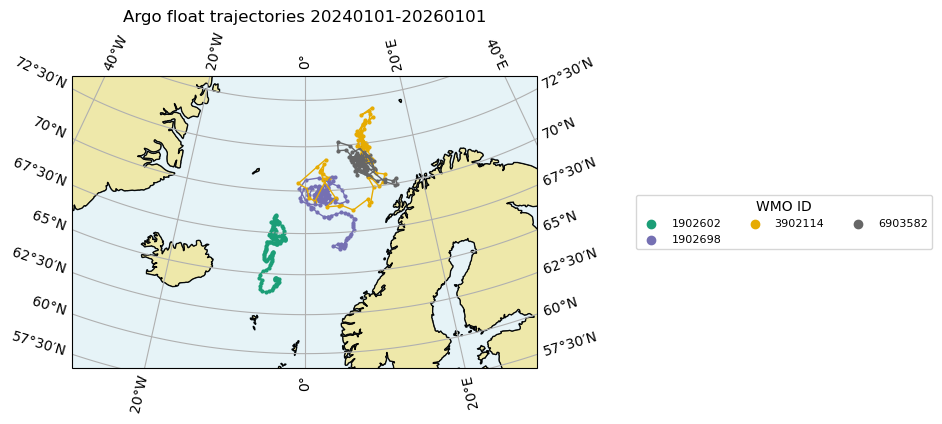

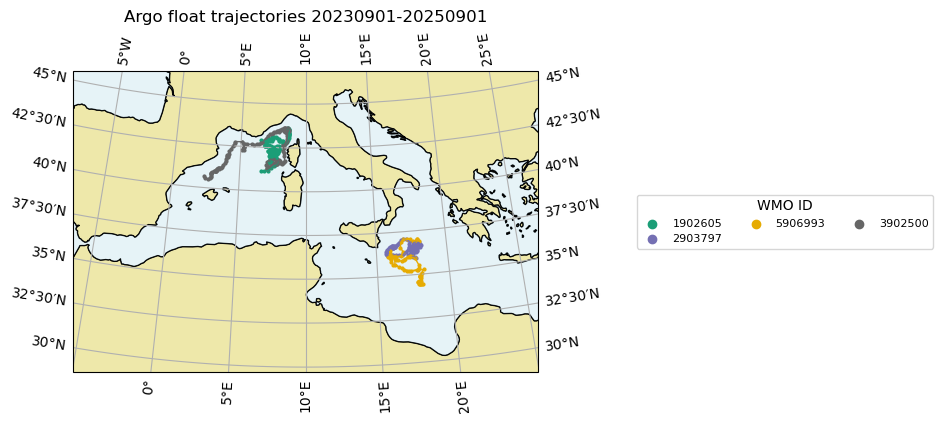

In [15]:
#-- Plot float trajectories

dict_cord_nor = {k: dict_cord[k] for k in wmo_nor}
dict_cord_med = {k: dict_cord[k] for k in wmo_med}

title = "Argo float trajectories 20240101-20260101"
list_extent = (-30, 30, 59, 75)
projection = ccrs.LambertConformal(central_longitude=0, central_latitude=65)
plot_trajectories(dict_cord_nor,title,list_extent,projection,ax=None)

title = "Argo float trajectories 20230901-20250901"
list_extent = (-5, 25, 29, 46)
projection = ccrs.LambertConformal(central_longitude=10, central_latitude=40)
plot_trajectories(dict_cord_med,title,list_extent,projection,ax=None)

1902602
1902698
3902114
6903582
1902605
2903797
5906993
3902500


/tmp/ipykernel_3271/240065158.py:53: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axs = plt.subplots(1, 2, figsize=(13, 2.5))


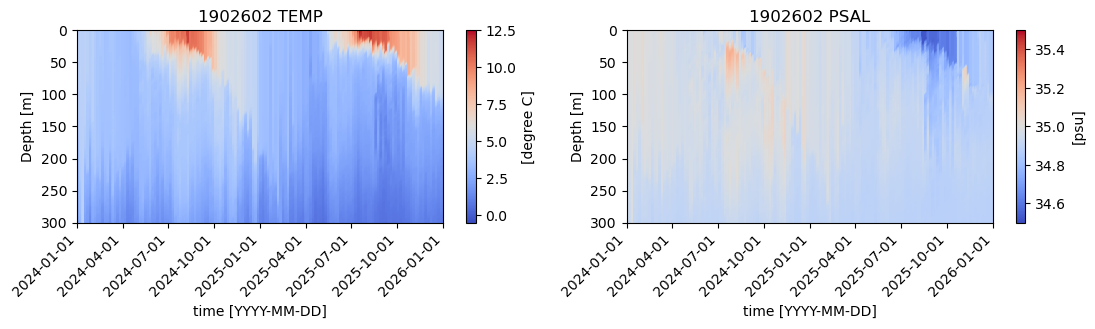

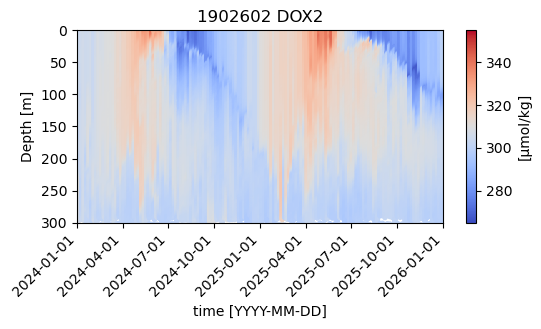

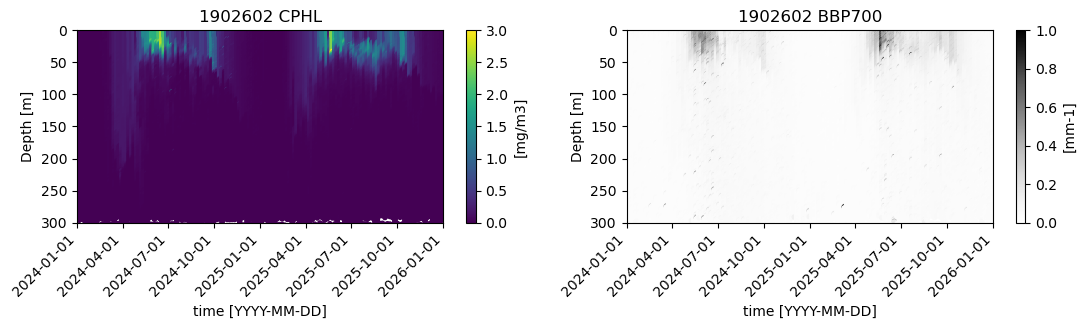

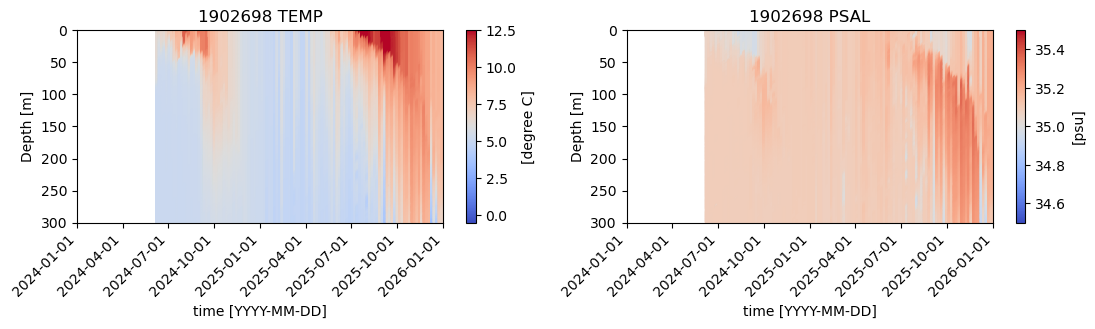

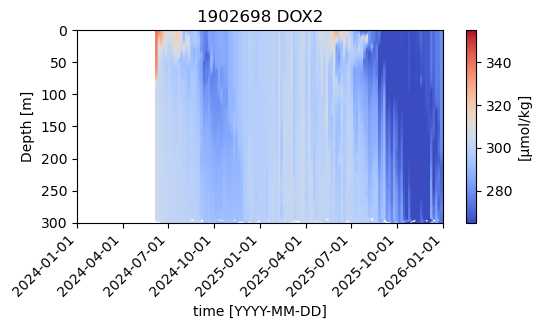

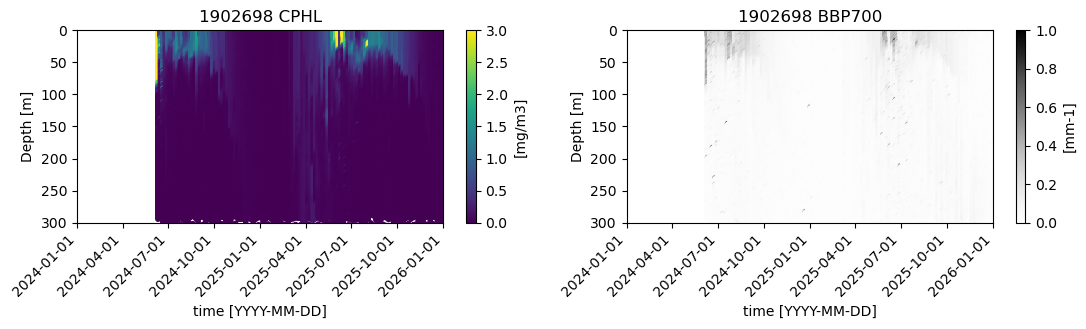

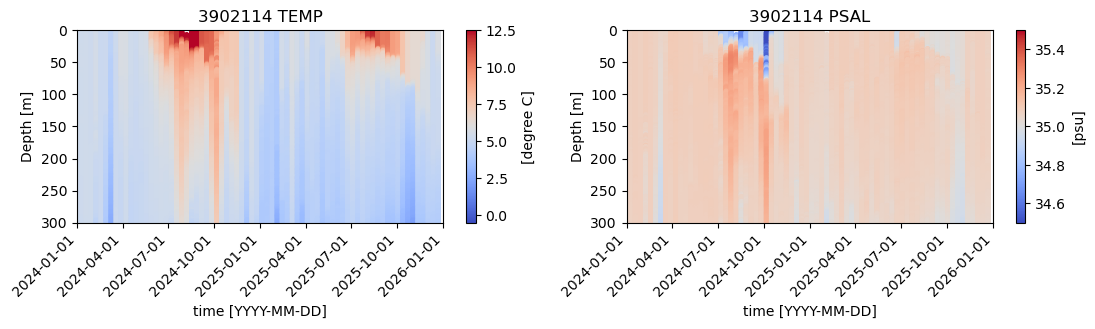

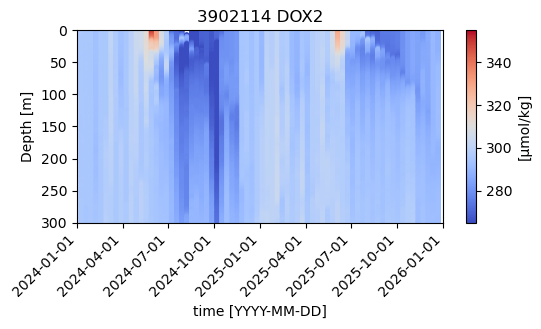

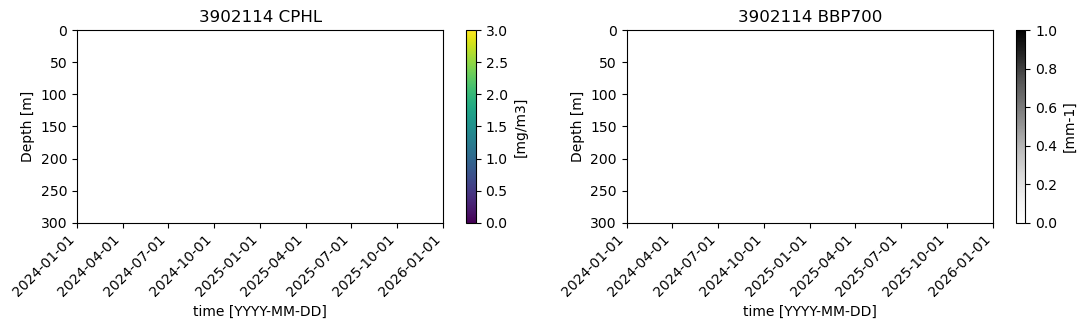

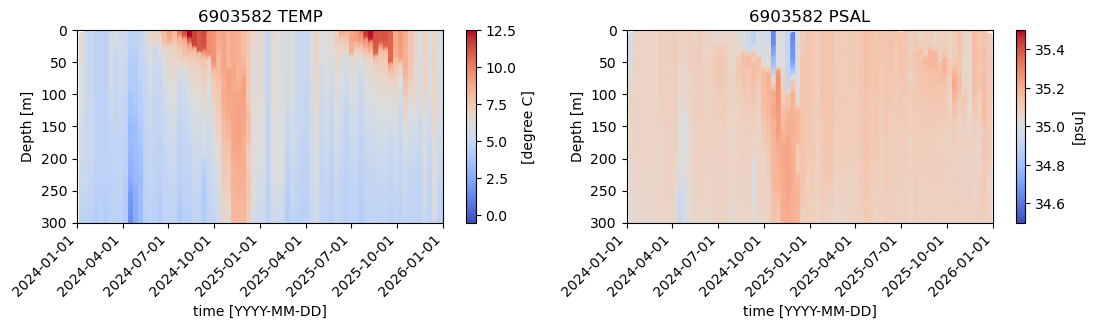

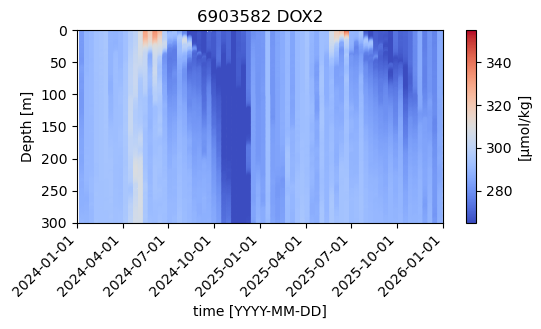

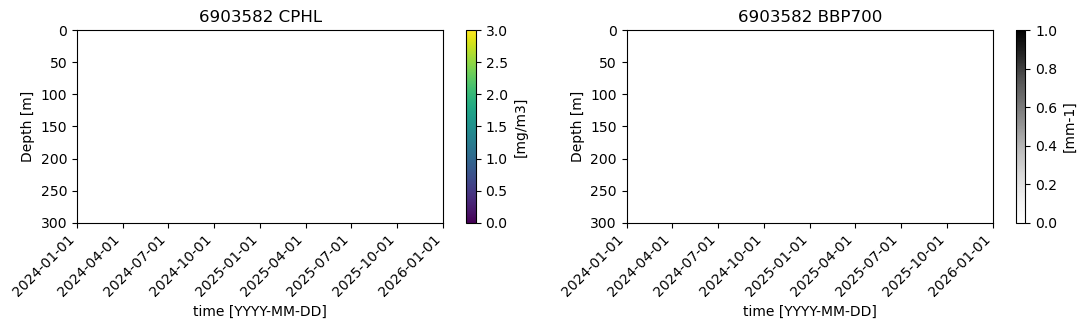

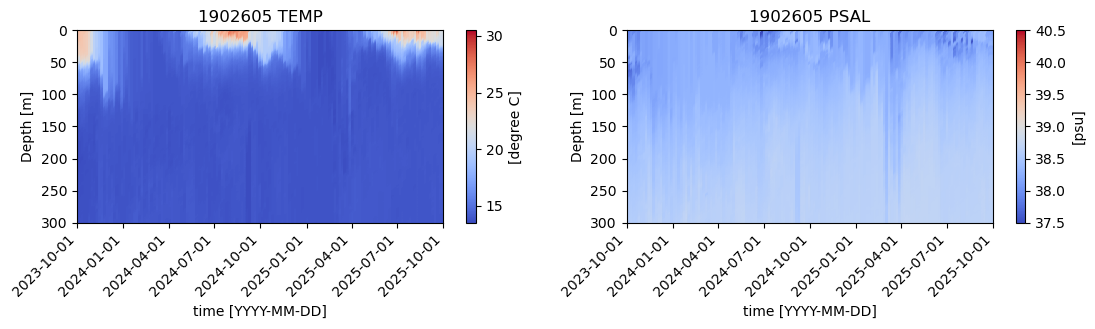

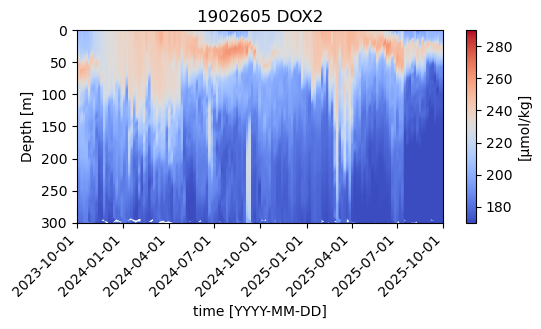

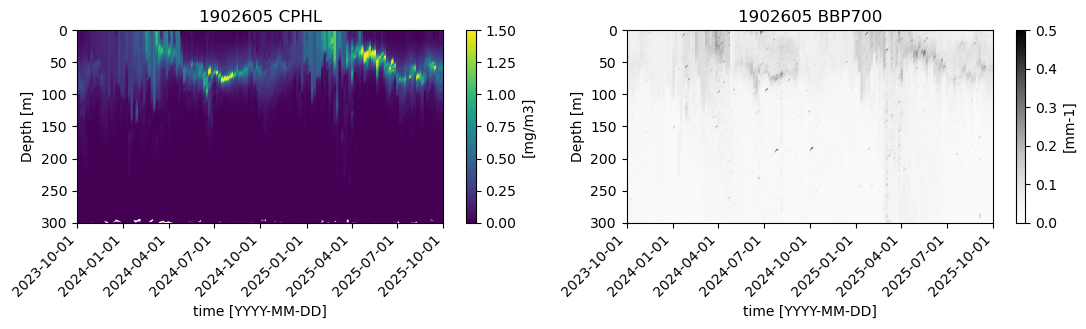

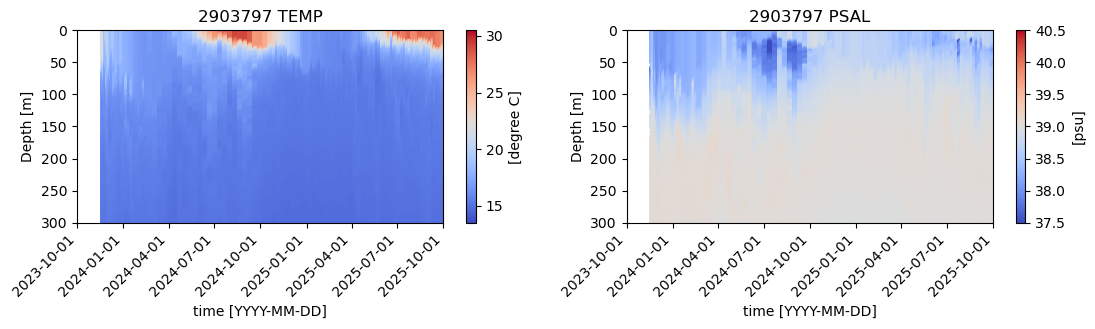

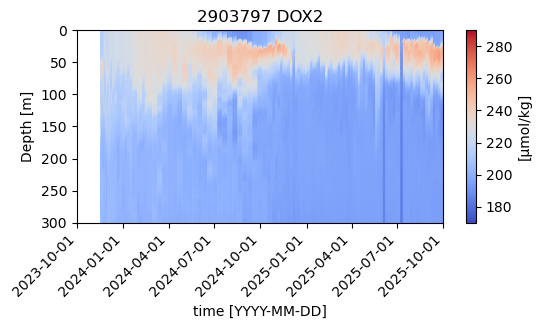

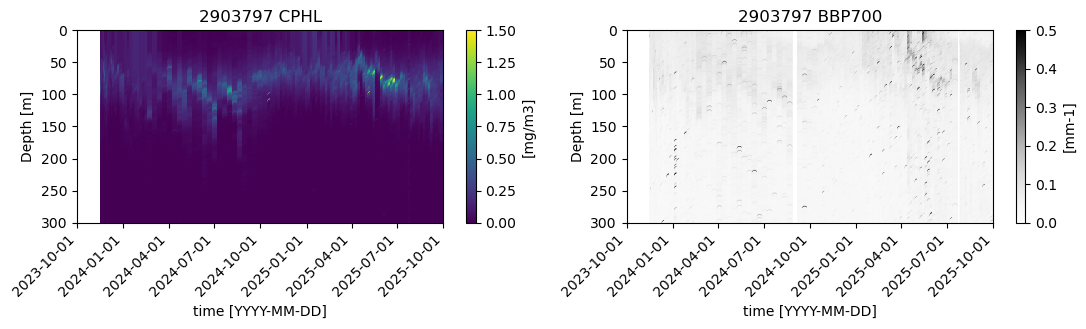

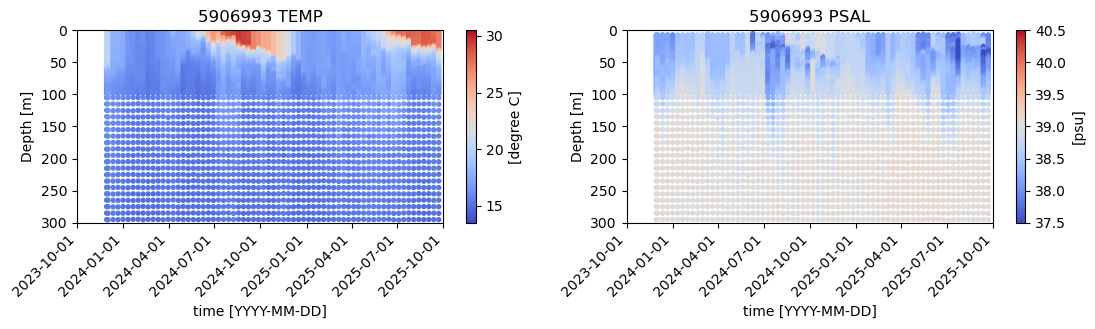

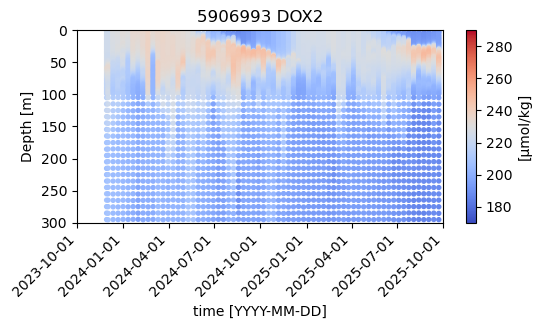

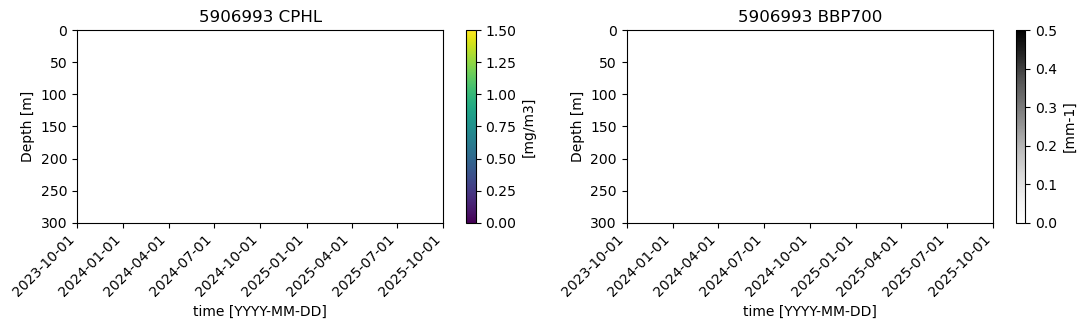

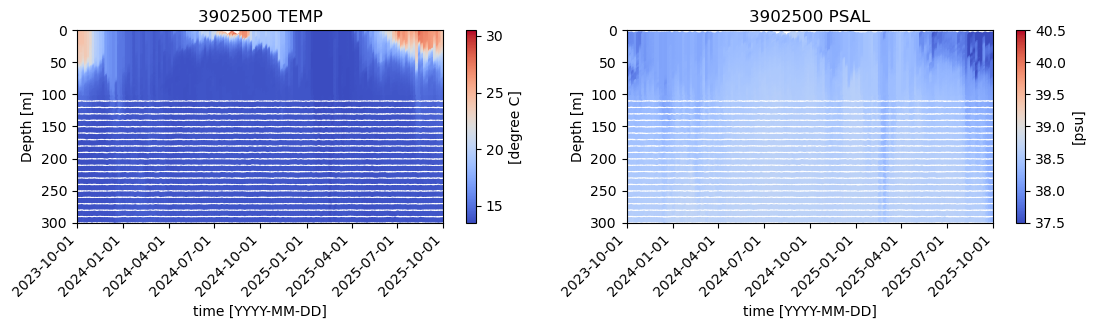

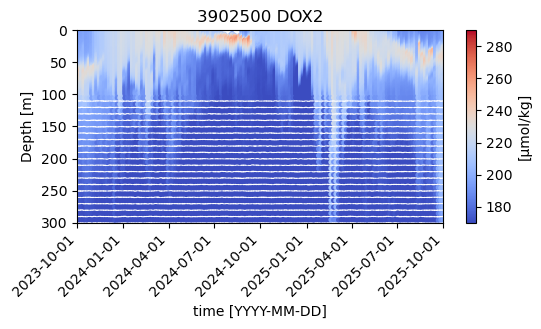

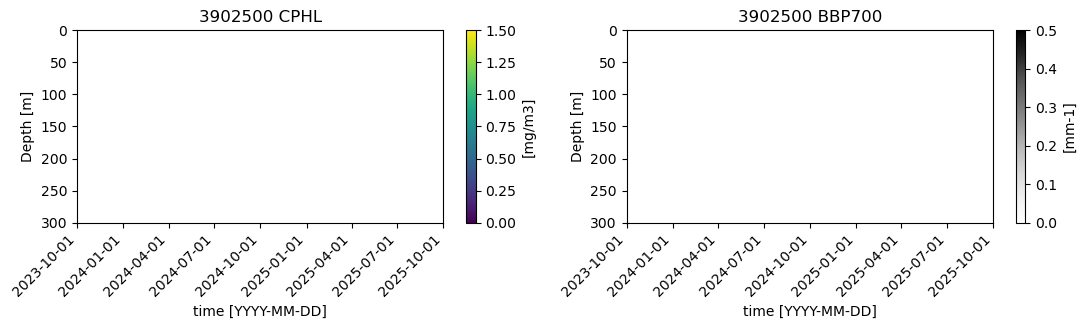

In [16]:
#-- Plot section along float 

temp_range = {
    **dict.fromkeys(wmo_nor, (-0.5, 12.5)),
    **dict.fromkeys(wmo_med, (13.5, 30.5))
}

psal_range = {
    **dict.fromkeys(wmo_nor, (34.5, 35.5)),
    **dict.fromkeys(wmo_med, (37.5, 40.5))
}

dox2_range = {
    **dict.fromkeys(wmo_nor, (265, 355)),
    **dict.fromkeys(wmo_med, (170, 290))
}

chla_range = {
    **dict.fromkeys(wmo_nor, (0, 3.0)),
    **dict.fromkeys(wmo_med, (0, 1.5))
}

bbp7_range = {
    **dict.fromkeys(wmo_nor, (0, 1.0)),
    **dict.fromkeys(wmo_med, (0, 0.5))
}

dpth_range = [0.0, 300.0] # dBar (=meter)

for wmo_id in wmo_ids:
    print(wmo_id)

    temp = dict_temp[wmo_id]
    psal = dict_psal[wmo_id]
    dox2 = dict_dox2[wmo_id]
    chla = dict_chla[wmo_id]
    bbp7 = dict_bbp7[wmo_id]
    prss = dict_prss[wmo_id]
    date = dict_date[wmo_id]
    #print(date[0,0],date[-1,0])
    #inspect_array(chla)
    
    fig, axs = plt.subplots(1, 2, figsize=(13, 2.5))
    plot_profiles(date, prss, temp, axs[0], 'coolwarm', '[degree C]', f"{wmo_id} TEMP", dpth_range, temp_range[wmo_id], date_range[wmo_id])
    plot_profiles(date, prss, psal, axs[1], 'coolwarm', '[psu]',      f"{wmo_id} PSAL", dpth_range, psal_range[wmo_id], date_range[wmo_id])
    
    fig, axs = plt.subplots(1, 2, figsize=(13, 2.5))
    plot_profiles(date, prss, dox2, axs[0], 'coolwarm',  '[µmol/kg]', f"{wmo_id} DOX2", dpth_range, dox2_range[wmo_id], date_range[wmo_id])
    axs[1].set_visible(False)

    if (np.ma.count(chla) > 0) or (np.ma.count(bbp7) > 0):
        
        fig, axs = plt.subplots(1, 2, figsize=(13, 2.5))
        if np.ma.count(chla) == 0:
            axs[0].set_visible(False)
        else:
            plot_profiles(date, prss, chla, axs[0], 'viridis',  '[mg/m3]', f"{wmo_id} CPHL", dpth_range, chla_range[wmo_id], date_range[wmo_id])
        if np.ma.count(bbp7) == 0:
            axs[1].set_visible(False)
        else:
            plot_profiles(date, prss, bbp7, axs[1], 'Greys',    '[mm-1]',  f"{wmo_id} BBP700", dpth_range, bbp7_range[wmo_id], date_range[wmo_id])